<a href="https://colab.research.google.com/github/VakhromeevaKate/python-practice-algos/blob/master/practice5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
%pip install medmnist --quiet

# Med Mnist Dataset


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score

In [ ]:
import medmnist
from medmnist import INFO, PneumoniaMNIST

In [ ]:
# Loading dataset
data_flag = 'pneumoniamnist'
info = INFO[data_flag]
print(f"Задача: {info['task']}")
print(f"Классы: {info['label']}")

Задача: binary-class
Классы: {'0': 'normal', '1': 'pneumonia'}


In [ ]:
# Data
from medmnist import PneumoniaMNIST

train_dataset = PneumoniaMNIST(split='train', download=True, size=28)
val_dataset   = PneumoniaMNIST(split='val',   download=True, size=28)
test_dataset  = PneumoniaMNIST(split='test',  download=True, size=28)

In [ ]:
X_train = train_dataset.imgs.reshape(len(train_dataset), -1).astype(np.float32)
y_train = train_dataset.labels.ravel()
X_val   = val_dataset.imgs.reshape(len(val_dataset), -1).astype(np.float32)
y_val   = val_dataset.labels.ravel()
X_test  = test_dataset.imgs.reshape(len(test_dataset), -1).astype(np.float32)
y_test  = test_dataset.labels.ravel()

print(f"Train: {X_train.shape}, Val: {X_val.shape}, Test: {X_test.shape}")

Train: (4708, 784), Val: (524, 784), Test: (624, 784)


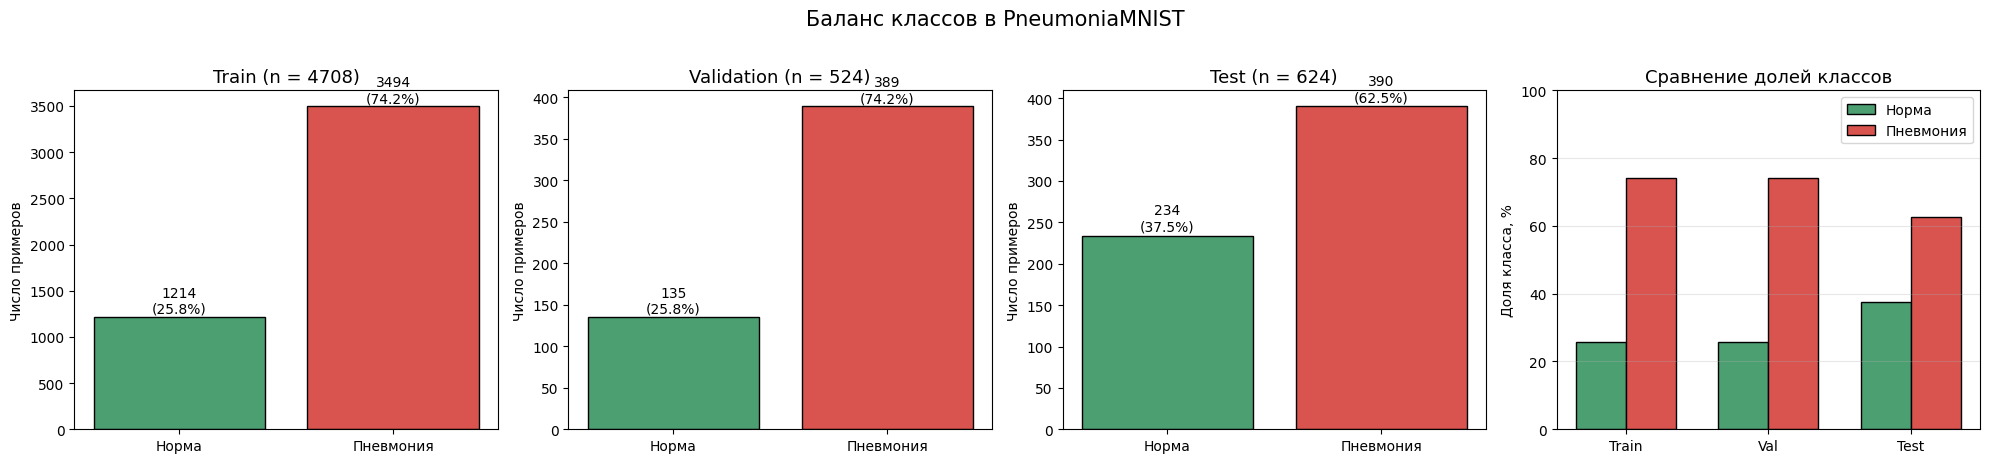


БАЛАНС КЛАССОВ
Train : всего =  4708 | норма =  1214 | пневмония =  3494 | доля пневмонии = 74.21%
Val   : всего =   524 | норма =   135 | пневмония =   389 | доля пневмонии = 74.24%
Test  : всего =   624 | норма =   234 | пневмония =   390 | доля пневмонии = 62.50%


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

def plot_class_balance(y_train, y_val, y_test, class_names=("Норма", "Пневмония")):
    """
    Рисует три подграфика: распределение классов в train/val/test,
    а также сравнивает доли классов между выборками.
    """
    fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))

    datasets = [
        ("Train", y_train, axes[0]),
        ("Validation", y_val, axes[1]),
        ("Test", y_test, axes[2]),
    ]

    for name, y, ax in datasets:
        counts = Counter(y)
        classes = sorted(counts.keys())
        labels = [class_names[c] for c in classes]
        values = [counts[c] for c in classes]
        total = sum(values)
        colors = ['#4C9F70', '#D9534F']  # зелёный — норма, красный — пневмония

        bars = ax.bar(labels, values, color=colors, edgecolor='black')
        ax.set_title(f"{name} (n = {total})", fontsize=13)
        ax.set_ylabel("Число примеров")
        for bar, v in zip(bars, values):
            pct = 100 * v / total
            ax.text(bar.get_x() + bar.get_width() / 2,
                    v + total * 0.01,
                    f"{v}\n({pct:.1f}%)",
                    ha='center', fontsize=10)

    # 4-й график: сравнение долей классов по выборкам
    ax = axes[3]
    splits = ["Train", "Val", "Test"]
    data = [y_train, y_val, y_test]
    ratios_pos = [100 * np.mean(y) for y in data]  # доля класса 1 (пневмония)

    x = np.arange(len(splits))
    width = 0.35
    ax.bar(x - width/2, [100 - r for r in ratios_pos], width,
           label=class_names[0], color='#4C9F70', edgecolor='black')
    ax.bar(x + width/2, ratios_pos, width,
           label=class_names[1], color='#D9534F', edgecolor='black')
    ax.set_xticks(x)
    ax.set_xticklabels(splits)
    ax.set_ylabel("Доля класса, %")
    ax.set_title("Сравнение долей классов", fontsize=13)
    ax.legend()
    ax.grid(axis='y', alpha=0.3)
    ax.set_ylim(0, 100)

    plt.suptitle("Баланс классов в PneumoniaMNIST", fontsize=15, y=1.02)
    plt.tight_layout()
    plt.show()

    # Печатаем числовые метрики
    print("\n" + "="*60)
    print("БАЛАНС КЛАССОВ")
    print("="*60)
    for name, y in zip(["Train", "Val", "Test"], [y_train, y_val, y_test]):
        pos = int(np.sum(y))
        neg = len(y) - pos
        ratio = pos / len(y)
        print(f"{name:6s}: всего = {len(y):5d} | "
              f"норма = {neg:5d} | пневмония = {pos:5d} | "
              f"доля пневмонии = {ratio:.2%}")


plot_class_balance(y_train, y_val, y_test)

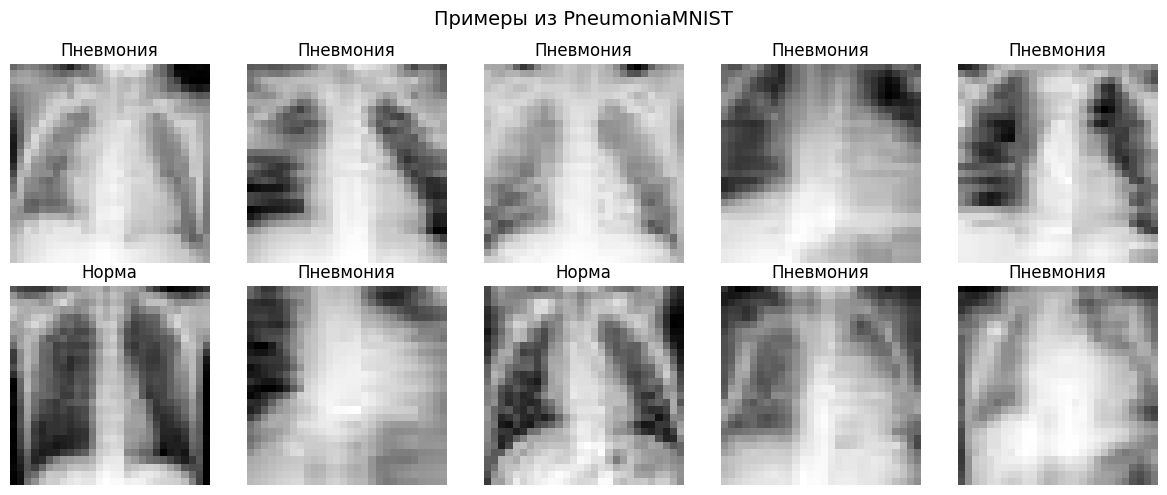

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(X_train[i].reshape(28, 28), cmap='gray')
    ax.set_title("Пневмония" if y_train[i] == 1 else "Норма")
    ax.axis('off')
plt.suptitle("Примеры из PneumoniaMNIST", fontsize=14)
plt.tight_layout()
plt.show()

In [ ]:
# Дерево без ограничений — переобучается
tree_full = DecisionTreeClassifier(class_weight='balanced', random_state=42)
tree_full.fit(X_train, y_train)

train_acc = accuracy_score(y_train, tree_full.predict(X_train))
val_acc   = accuracy_score(y_val,   tree_full.predict(X_val))
print(f"Дерево (без ограничений): train={train_acc:.3f}, val={val_acc:.3f}")

# Дерево с ограничением глубины
tree_shallow = DecisionTreeClassifier(class_weight='balanced', max_depth=7, random_state=42)
tree_shallow.fit(X_train, y_train)

train_acc = accuracy_score(y_train, tree_shallow.predict(X_train))
val_acc   = accuracy_score(y_val,   tree_shallow.predict(X_val))
print(f"Дерево (max_depth=5):     train={train_acc:.3f}, val={val_acc:.3f}")

Дерево (без ограничений): train=1.000, val=0.901
Дерево (max_depth=5):     train=0.971, val=0.899


In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(class_weight='balanced', n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

train_acc = accuracy_score(y_train, rf.predict(X_train))
val_acc   = accuracy_score(y_val,   rf.predict(X_val))
print(f"Random Forest: train={train_acc:.3f}, val={val_acc:.3f}")

Random Forest: train=1.000, val=0.954


In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(class_weight='balanced', max_depth=7,  n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

train_acc = accuracy_score(y_train, rf.predict(X_train))
val_acc   = accuracy_score(y_val,   rf.predict(X_val))
print(f"Random Forest: train={train_acc:.3f}, val={val_acc:.3f}")

Random Forest: train=0.977, val=0.945


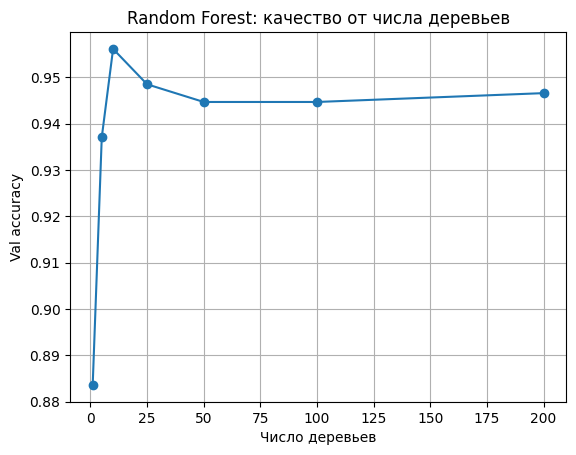

In [ ]:
# Зависимость качества от числа деревьев
n_range = [1, 5, 10, 25, 50, 100, 200]
val_scores = []
for n in n_range:
    rf_n = RandomForestClassifier(class_weight='balanced', max_depth=7, n_estimators=n, random_state=42)
    rf_n.fit(X_train, y_train)
    val_scores.append(accuracy_score(y_val, rf_n.predict(X_val)))

plt.plot(n_range, val_scores, marker='o')
plt.xlabel("Число деревьев")
plt.ylabel("Val accuracy")
plt.title("Random Forest: качество от числа деревьев")
plt.grid(True)
plt.show()

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

gb = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1,
                                 max_depth=3, random_state=42)
gb.fit(X_train, y_train)

train_acc = accuracy_score(y_train, gb.predict(X_train))
val_acc   = accuracy_score(y_val,   gb.predict(X_val))
print(f"Gradient Boosting: train={train_acc:.3f}, val={val_acc:.3f}")

Gradient Boosting: train=0.991, val=0.960


In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

gb = GradientBoostingClassifier(n_estimators=10, learning_rate=0.1,
                                 max_depth=3, random_state=42)
gb.fit(X_train, y_train)

train_acc = accuracy_score(y_train, gb.predict(X_train))
val_acc   = accuracy_score(y_val,   gb.predict(X_val))
print(f"Gradient Boosting: train={train_acc:.3f}, val={val_acc:.3f}")

Gradient Boosting: train=0.927, val=0.910


# Metrics and Comparison

```
# Выбран кодовый формат
```



In [ ]:
models = {
    "Decision Tree (full)":    tree_full,
    "Decision Tree (depth=5)": tree_shallow,
    "Random Forest":           rf,
    "Gradient Boosting":       gb,
}

for name, model in models.items():
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    f1  = f1_score(y_test, y_pred, average='binary')
    print(f"{name:30s} | accuracy={acc:.3f} | F1={f1:.3f}")

# Детальный отчёт
print("\n", classification_report(y_test, gb.predict(X_test),
                                  target_names=['Норма', 'Пневмония']))

Decision Tree (full)           | accuracy=0.779 | F1=0.840
Decision Tree (depth=5)        | accuracy=0.806 | F1=0.855
Random Forest                  | accuracy=0.851 | F1=0.887
Gradient Boosting              | accuracy=0.758 | F1=0.836

               precision    recall  f1-score   support

       Норма       0.94      0.38      0.54       234
   Пневмония       0.73      0.98      0.84       390

    accuracy                           0.76       624
   macro avg       0.83      0.68      0.69       624
weighted avg       0.81      0.76      0.73       624



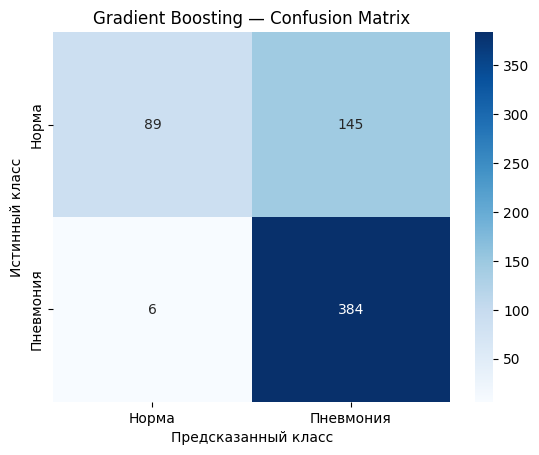

In [ ]:
import seaborn as sns

cm = confusion_matrix(y_test, gb.predict(X_test))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Норма', 'Пневмония'],
            yticklabels=['Норма', 'Пневмония'])
plt.ylabel("Истинный класс")
plt.xlabel("Предсказанный класс")
plt.title("Gradient Boosting — Confusion Matrix")
plt.show()